# 11주차 이론 · 데이터 요약과 시각화

교육용으로 만든 교내 카페 주문 데이터로 그래프를 그리고 읽는 방법을 익힙니다. 실제 개인이나 사업장의 기록이 아닙니다.

**사용법**
- 코드 셀은 **위에서 아래로 차례로** 실행합니다.
- 각 항목은 `코드 → 코드 설명 → 결과 해석` 순서입니다.
- 그래프 코드에서 **핵심은 첫 줄**입니다. 제목과 축 이름을 붙이는 `decorate(...)` 줄은 그래프마다 글자만 바꿔 쓰며, 안의 내용을 이해하지 않아도 됩니다.
- **(선택)** 표시가 붙은 항목은 건너뛰어도 뒤의 내용을 이해하는 데 문제가 없습니다.

## 목차

1. 분석 질문과 데이터 점검 복습
2. 분석 질문과 그래프 연결
3. 데이터 불러오기와 구조 확인
4. 데이터 품질 점검
5. 데이터 정제
6. 범주형 데이터와 막대그래프
7. 연속형 데이터와 히스토그램
8. 그룹별 분포와 상자그림
9. 시간대별 변화 확인하기
10. 시간의 흐름과 선그래프
11. 두 수치의 관계와 산점도
12. 두 범주를 함께 비교하기 (선택)
13. 그래프를 문장으로 해석하기
14. 그래프 표현 방식 점검하기
15. 분석 결과 종합 확인하기

## 1. 분석 질문과 데이터 점검 복습

### 1-1. 분석 질문의 다섯 요소

그래프를 먼저 그리는 것이 아니라, 모호한 문제를 **대상·측정값·기준·계산·범위**가 드러나는 질문으로 바꾼 뒤 그 질문에 필요한 데이터가 있는지 확인합니다.

> 모호한 문제: 카페가 혼잡하다.
>
> 분석 질문: 카페의 시간대별 평균 대기시간은 어떻게 다르며, 평균 대기시간이 가장 긴 시간대는 언제인가?

| 요소 | 이 질문에서 |
|---|---|
| 대상 | 카페 주문 한 건 |
| 측정값 | 대기시간 |
| 기준 | 주문 시간대 |
| 계산 | 평균 |
| 범위 | 데이터에 기록된 기간과 매장 |

## 2. 분석 질문과 그래프 연결

### 2-1. 질문에 맞는 그래프 선택

그래프의 종류는 취향이 아니라 **질문의 목적과 데이터의 성격**에 따라 정합니다.

| 확인하려는 내용 | 알맞은 그래프 | 대표 질문 |
|---|---|---|
| 범주별 크기 비교 | 막대그래프 | 어떤 메뉴의 주문이 가장 많은가? |
| 값의 분포 | 히스토그램 | 대기시간은 어느 구간에 많이 모여 있는가? |
| 그룹별 분포 비교 | 상자그림 | 매장별 대기시간 분포는 어떻게 다른가? |
| 시간대·날짜에 따른 변화 | 선그래프, 막대그래프 | 시간대별 평균 대기시간은 어떻게 변하는가? |
| 두 수치의 관계 | 산점도 | 주문이 많을수록 대기시간이 길어지는가? |

질문을 먼저 적고, 그 질문에 답할 수 있는 그래프를 고릅니다.

## 3. 데이터 불러오기와 구조 확인

### 3-1. 분석 환경 준비

분석에 필요한 도구를 불러오고, 한글이 그래프에서 깨지지 않도록 글꼴을 설정합니다. 아래 코드는 컴퓨터에 설치된 한글 글꼴을 찾아 사용합니다. `decorate()`와 `show_values()`는 그래프에 제목·축 이름과 막대 값을 붙이는 **도우미 함수**입니다. 내용은 이해하지 않아도 됩니다.

Colab에서는 한글 글꼴이 기본으로 없으므로 다음 두 줄을 **먼저 실행한 뒤 런타임을 다시 시작**합니다.

```
!apt-get -qq -y install fonts-nanum
!fc-cache -fv
```

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

installed_fonts = {font.name for font in fm.fontManager.ttflist}
for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if font_name in installed_fonts:
        plt.rcParams["font.family"] = font_name
        print("사용하는 글꼴:", font_name)
        break
else:
    print("한글 글꼴을 찾지 못했습니다. 그래프의 한글이 깨지면 글꼴을 설치하세요.")

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 20)


# 그래프 도우미 함수 (이해하지 않아도 됩니다)
def decorate(ax, title, xlabel, ylabel, rotate=0):
    ax.set_title(title, pad=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=rotate)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()


def show_values(ax, fmt="{:,.0f}"):
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, padding=3)

사용하는 글꼴: Malgun Gothic


### 3-2. CSV 파일 불러오기

CSV 파일을 읽어 `raw`에 저장합니다. 컴퓨터에서 파일을 찾고, 없으면 인터넷에서 내려받습니다.

In [2]:
URL = "https://raw.githubusercontent.com/phyzikyh/computing/main/%EA%B0%95%EC%9D%98%EA%B5%90%EC%9E%AC/data/week11_cafe_orders.csv"


def find_file(name):
    starts = [Path.cwd()]
    notebook = globals().get("__vsc_ipynb_file__")      # VS Code에서 노트북이 있는 위치
    if notebook:
        starts.insert(0, Path(notebook).parent)
    for start in starts:
        for folder in [start, *start.parents][:4]:
            for sub in ["", "data", "강의교재/data"]:
                path = folder / sub / name
                if path.exists():
                    return path
    return None


data_path = find_file("week11_cafe_orders.csv")
source = data_path if data_path else URL          # 컴퓨터에 없으면 인터넷에서 내려받습니다.
raw = pd.read_csv(source, encoding="utf-8-sig")
print("불러온 파일:", source)
print(f"행: {raw.shape[0]:,}개, 열: {raw.shape[1]}개")

불러온 파일: ..\강의교재\data\week11_cafe_orders.csv
행: 103,812개, 열: 15개


### 3-3. head()와 tail()로 데이터 미리보기

처음 다섯 행을 봅니다. 한 행이 무엇을 뜻하는지부터 확인합니다.

In [3]:
raw.head()

,order_id,order_date,order_time,weekday,order_hour,store_location,menu_name,order_count,unit_price,sales_amount,wait_minutes,payment_method,weather,event_day,staff_count
0,2526,2026-03-02,09:01:32,월,9,공학관점,아메리카노,1,2500,2500,3.3,NaN,비,행사,3
1,2015,2026-03-02,09:01:51,월,9,학생회관점,카페라테,1,3500,3500,9.0,NaN,비,행사,2
2,2289,2026-03-02,09:01:56,월,9,도서관점,바닐라라테,2,4000,8000,5.2,카드,NaN,행사,3
3,2527,2026-03-02,09:04:47,월,9,공학관점,바닐라라테,1,4000,4000,4.0,NaN,비,행사,3
4,2524,2026-03-02,09:05:14,월,9,공학관점,바닐라라테,1,4000,4000,5.5,카드,NaN,행사,3


**코드 설명**
- `raw.head()`는 처음 5행을 보여 줍니다.

**결과 해석**
- 한 행은 **주문 한 건**입니다. 날짜, 시각, 매장, 메뉴, 수량, 단가, 매출액, 대기시간, 결제수단, 날씨, 행사 여부, 직원 수가 한 줄에 기록되어 있습니다.
- 첫 행은 2026-03-02 오전 9시대입니다.

In [4]:
raw.tail()

,order_id,order_date,order_time,weekday,order_hour,store_location,menu_name,order_count,unit_price,sales_amount,wait_minutes,payment_method,weather,event_day,staff_count
103807,105184,2026-08-28,18:55:23,금,18,도서관점,아메리카노,1,2500,2500,3.0,카드,구름많음,일반,3
103808,105494,2026-08-28,18:55:26,금,18,공학관점,카페라테,1,3500,3500,6.6,카드,구름많음,일반,2
103809,105494,2026-08-28,18:55:26,금,18,공학관점,카페라테,1,3500,3500,6.6,카드,구름많음,일반,2
103810,105488,2026-08-28,18:55:37,금,18,공학관점,아메리카노,3,2500,7500,6.8,카드,NaN,일반,2
103811,105482,2026-08-28,18:58:38,금,18,공학관점,바닐라라테,3,4000,12000,9.2,간편결제,NaN,일반,2


**코드 설명**
- `raw.tail()`은 마지막 5행을 보여 줍니다. `raw.tail(10)`처럼 행 수를 정할 수 있습니다.

**결과 해석**
- 마지막 행은 2026-08-28 오후 6시대입니다. 행은 주문 시각 순서로 놓여 있지만 `order_id`는 시간 순서와 같지 않습니다.
- 주문 번호 105494의 같은 행이 두 번 보입니다. 중복된 행일 수 있으므로 뒤에서 확인합니다.
- `weather`에 `NaN`(비어 있는 값)이 보입니다. 뒤에서 결측값으로 확인합니다.

### 3-4. 데이터 구조 확인하기

`info()`로 열 이름, 자료형, 비어 있지 않은 값의 개수를 한 번에 확인합니다.

In [5]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 103812 entries, 0 to 103811
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   order_id        103812 non-null  int64  
 1   order_date      103812 non-null  str    
 2   order_time      103812 non-null  str    
 3   weekday         103812 non-null  str    
 4   order_hour      103812 non-null  int64  
 5   store_location  103812 non-null  str    
 6   menu_name       103812 non-null  str    
 7   order_count     103812 non-null  int64  
 8   unit_price      103812 non-null  int64  
 9   sales_amount    103812 non-null  int64  
 10  wait_minutes    102777 non-null  float64
 11  payment_method  83112 non-null   str    
 12  weather         72762 non-null   str    
 13  event_day       103812 non-null  str    
 14  staff_count     103812 non-null  int64  
dtypes: float64(1), int64(6), str(8)
memory usage: 18.3 MB


**코드 설명**
- `Non-Null Count`는 비어 있지 않은 값의 개수이고, `Dtype`은 자료형입니다.

**결과 해석**
- `wait_minutes`, `payment_method`, `weather`는 전체 행보다 비어 있지 않은 값이 적습니다. 결측값이 있다는 뜻입니다.
- `order_date`는 날짜처럼 보이지만 문자열(`object` 또는 `str`)로 읽혔습니다.

## 4. 데이터 품질 점검

잘못된 값이나 중복 행을 확인하지 않으면 그래프도 잘못된 결론을 전달합니다. 결측값, 값의 범위, 중복값을 차례로 점검합니다.

### 4-1. 결측값 확인하기

In [6]:
quality_report = pd.DataFrame({
    "결측값": raw.isna().sum(),
    "결측률(%)": (raw.isna().mean() * 100).round(2),
})
quality_report[quality_report["결측값"] > 0]

,결측값,결측률(%)
wait_minutes,1035,1.00
payment_method,20700,19.94
weather,31050,29.91


**코드 설명**
- `raw.isna().sum()`은 열마다 비어 있는 값의 개수, `raw.isna().mean() * 100`은 그 비율(%)입니다.
- `pd.DataFrame({...})`은 두 결과를 나란히 놓은 표를 만들고, 마지막 줄은 결측이 있는 열만 보여 줍니다.

**결과 해석**
- `wait_minutes`는 약 1%이지만 `payment_method`는 약 20%, `weather`는 약 30%가 비어 있습니다.
- 결측이 많은 열을 어떻게 다룰지는 다음 항목에서 판단합니다.

### 4-2. 결측률이 높은 열 판단하기

행을 삭제하면 얼마나 줄어드는지 먼저 확인합니다. 결측이 있는 행을 모두 지우면 자료가 크게 줄고, 비어 있는 값을 한 가지 값으로 채우면 실제와 다른 결과가 나올 수 있습니다.

In [7]:
complete_rows = raw.dropna(subset=["payment_method", "weather"])
removed_rows = len(raw) - len(complete_rows)

print(f"원본 행 수: {len(raw):,}개")
print(f"두 열에 결측이 없는 행 수: {len(complete_rows):,}개")
print(f"삭제되는 행 수: {removed_rows:,}개")
print(f"삭제 비율: {removed_rows / len(raw) * 100:.1f}%")

원본 행 수: 103,812개
두 열에 결측이 없는 행 수: 52,062개
삭제되는 행 수: 51,750개
삭제 비율: 49.8%


**코드 설명**
- `dropna(subset=[...])`는 지정한 열이 비어 있는 행을 삭제합니다.
- `len()`은 행의 개수입니다.

**결과 해석**
- 두 열 중 하나라도 비어 있는 행을 지우면 **절반 가까이(49.8%)**가 사라집니다. 결제수단과 날씨는 삭제하지 않습니다.
- 비어 있는 값은 `미기록`이라는 별도 표시로 바꿔 행을 보존합니다. `미기록`은 실제 결제수단이나 날씨가 아니라 **기록되지 않았다는 데이터 상태의 표시**입니다.

### 4-3. 범위 오류와 중복 확인하기

주문 수량은 1~6개이고 대기시간은 0보다 커야 합니다. 이 범위를 벗어난 값과 완전히 같은 행을 찾습니다. 30분을 넘는 대기시간은 실제로 일어날 수 있으므로 오류로 단정하지 않고 **확인이 필요한 값**으로 둡니다.

In [8]:
bad_order = raw[(raw["order_count"] < 1) | (raw["order_count"] > 6)]
negative_wait = raw[raw["wait_minutes"] < 0]
long_wait = raw[raw["wait_minutes"] > 30]

print("완전히 같은 중복 행:", raw.duplicated().sum(), "건")
print("주문 수량이 1~6이 아닌 행:", len(bad_order), "건")
print("음수 대기시간:", len(negative_wait), "건")
print("30분 초과 대기시간:", len(long_wait), "건")

long_wait.sort_values("wait_minutes", ascending=False)[
    ["order_id", "order_date", "store_location", "menu_name", "wait_minutes"]
].head()

완전히 같은 중복 행: 311 건
주문 수량이 1~6이 아닌 행: 52 건
음수 대기시간: 31 건
30분 초과 대기시간: 207 건


,order_id,order_date,store_location,menu_name,wait_minutes
94447,96258,2026-08-13,공학관점,바닐라라테,74.9
75933,77325,2026-07-10,학생회관점,아메리카노,74.8
100418,102232,2026-08-24,공학관점,바닐라라테,74.8
43611,45575,2026-05-18,공학관점,카페라테,74.7
13677,15396,2026-03-25,학생회관점,아메리카노,74.3


**코드 설명**
- `raw[조건]`은 조건이 참인 행만 가져옵니다. `|`는 '또는'입니다. 앞에서 배운 조건 추출입니다.
- `duplicated().sum()`은 완전히 같은 행의 개수, `sort_values()`는 큰 값부터 정렬합니다.

**결과 해석**
- 중복 311건, 수량 오류 52건, 음수 대기시간 31건은 **실제로 있을 수 없는 값**이므로 정제합니다.
- 30분 초과 207건은 혼잡할 때 실제로 생길 수 있어 삭제하지 않습니다.

## 5. 데이터 정제

### 5-1. 원본을 두고 정제한 데이터 만들기

원본 `raw`는 그대로 두고, 정제한 결과를 새 이름 `data`에 저장합니다. 아래 코드는 이미 작성되어 있으며 **실행만 하면 됩니다.** 하는 일은 다음과 같습니다.

1. 완전히 같은 중복 행을 하나만 남깁니다. (`drop_duplicates`)
2. 주문 수량이 1~6인 행만 남깁니다.
3. 음수 대기시간은 삭제하지 않고 비어 있는 값(`np.nan`)으로 바꿉니다. 행은 보존하고 평균 계산에서만 빠집니다.
4. 문자열 날짜를 날짜 자료형으로 바꿉니다. (`pd.to_datetime`)
5. 비어 있는 결제수단과 날씨를 `미기록`으로 채웁니다. (`fillna`)

In [9]:
data = raw.drop_duplicates().copy()

data = data[(data["order_count"] >= 1) & (data["order_count"] <= 6)].copy()

data.loc[data["wait_minutes"] < 0, "wait_minutes"] = np.nan

data["order_date"] = pd.to_datetime(data["order_date"])

data["payment_method"] = data["payment_method"].fillna("미기록")
data["weather"] = data["weather"].fillna("미기록")

print(f"정제 전: {len(raw):,}행")
print(f"정제 후: {len(data):,}행")
print("날짜 범위:", data["order_date"].min().date(), "~", data["order_date"].max().date())
print("정제 후 결측값(결제수단, 날씨):", data[["payment_method", "weather"]].isna().sum().sum(), "개")

정제 전: 103,812행
정제 후: 103,449행
날짜 범위: 2026-03-02 ~ 2026-08-28
정제 후 결측값(결제수단, 날씨): 0 개


**결과 해석**
- 103,812행에서 중복과 수량 오류가 빠져 103,449행이 남았습니다.
- 원본 `raw`는 그대로이므로 정제 기준을 바꾸고 싶으면 `raw`에서 다시 시작할 수 있습니다.

### 5-2. 날씨의 종류와 기록 방식 확인하기 (선택)

날씨 열이 어떤 값으로 이루어져 있는지 확인합니다.

In [10]:
print("날씨의 종류와 기록 수:")
print(raw["weather"].value_counts())

weather_per_slot = raw.groupby(["order_date", "order_hour"])["weather"].nunique()
print()
print("같은 날짜·시간대에 서로 다른 날씨 값의 개수:")
print(weather_per_slot.value_counts())

날씨의 종류와 기록 수:
weather
맑음      31175
구름많음    21967
흐림      13132
비        6488
Name: count, dtype: int64

같은 날짜·시간대에 서로 다른 날씨 값의 개수:
weather
1    1300
Name: count, dtype: int64


**코드 설명**
- `value_counts()`는 값의 종류별 개수를 셉니다.
- `groupby(['order_date', 'order_hour'])`는 날짜와 시간대가 모두 같은 행끼리 묶습니다. `nunique()`는 묶음마다 서로 다른 값이 몇 개인지 셉니다.

**결과 해석**
- 날씨는 맑음, 구름많음, 흐림, 비 **네 종류**이고, 하루 안에서도 시간대에 따라 바뀝니다.
- 같은 날짜·시간대에는 날씨가 **하나뿐**이어서, 비어 있는 날씨는 같은 시간대의 다른 행에서 가져와 채울 수도 있습니다. 이 수업에서는 단순하게 `미기록`으로 둡니다.

### 5-3. 요약표 먼저 확인하기

그래프를 그리기 전에 먼저 요약표를 만듭니다. 요약표는 그래프가 맞게 그려졌는지 검산하는 기준이 됩니다.

In [11]:
data[["order_count", "sales_amount", "wait_minutes", "staff_count"]].describe().round(2)

,order_count,sales_amount,wait_minutes,staff_count
count,103449.0,103449.00,102384.00,103449.00
mean,1.4,4326.48,5.98,3.27
std,0.6,2058.76,3.21,0.57
min,1.0,2500.00,1.00,2.00
25%,1.0,2500.00,4.10,3.00
50%,1.0,3500.00,5.60,3.00
75%,2.0,5000.00,7.50,4.00
max,3.0,12000.00,74.90,4.00


**코드 설명**
- `describe()`는 개수, 평균, 표준편차, 최솟값, 사분위수, 최댓값을 한 번에 보여 줍니다. 앞에서 사용한 방법입니다.

**결과 해석**
- 대기시간은 평균이 약 6분이고 최솟값은 1분, 최댓값은 70분을 넘습니다. 이 최댓값이 앞에서 본 30분 초과 값입니다.

## 6. 범주형 데이터와 막대그래프

### 6-1. 범주별 크기 비교하기

막대그래프는 **서로 구분되는 범주의 크기**를 비교합니다. 메뉴, 매장, 결제수단처럼 순서가 없는 범주형 데이터에 맞습니다. 가로축에 범주, 세로축에 비교할 값을 놓고 막대가 길수록 값이 큽니다. 아래는 원리를 확인하는 **세 개짜리 간단한 예제**입니다.

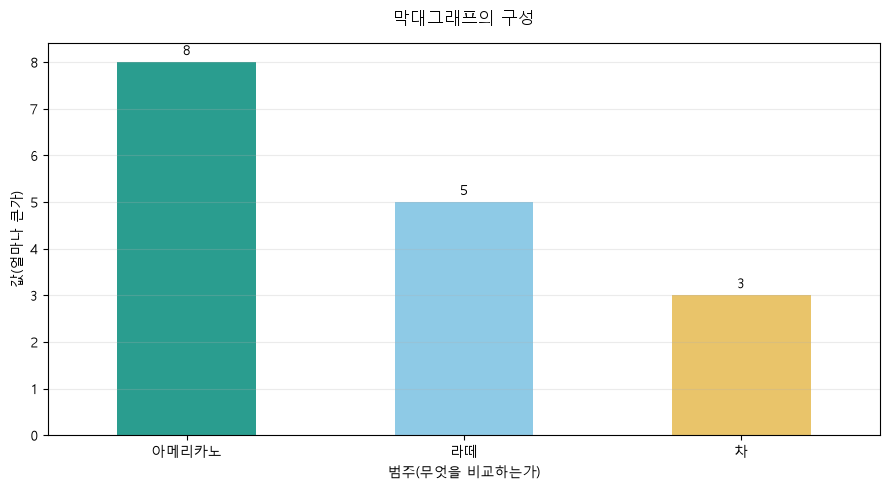

In [12]:
example_menu = pd.Series({"아메리카노": 8, "라떼": 5, "차": 3})

ax = example_menu.plot(kind="bar", color=["#2A9D8F", "#8ECAE6", "#E9C46A"])
show_values(ax)
decorate(ax, "막대그래프의 구성", "범주(무엇을 비교하는가)", "값(얼마나 큰가)")
plt.show()

**코드 설명**
- 핵심은 첫 줄입니다. `Series.plot(kind="bar")`는 Series를 막대그래프로 바꿉니다. 가로축은 이름(`index`), 막대의 높이는 값입니다.
- `show_values(ax)`는 막대 위에 값을 적고, `decorate(...)`는 제목과 축 이름을 붙입니다.

**결과 해석**
- 막대의 높이가 범주의 값입니다. 아메리카노(8)가 가장 높고 차(3)가 가장 낮습니다.

### 6-2. 실제 데이터로 막대그래프 만들기

실제 데이터의 한 행은 주문 한 건이므로, 메뉴별 주문량을 비교하려면 같은 메뉴의 `order_count`를 먼저 더해야 합니다.

In [13]:
menu_orders = data.groupby("menu_name")["order_count"].sum().sort_values(ascending=False)
menu_orders

menu_name
아메리카노    62045
카페라테     40806
바닐라라테    24393
녹차       17355
Name: order_count, dtype: int64

**코드 설명**
- `groupby('menu_name')`은 같은 메뉴끼리 묶고, `['order_count'].sum()`은 묶음마다 주문 수량을 더합니다.
- `sort_values(ascending=False)`는 큰 값부터 정렬합니다.

**결과 해석**
- 아메리카노 62,045개, 카페라테 40,806개, 바닐라라테 24,393개, 녹차 17,355개 순입니다.

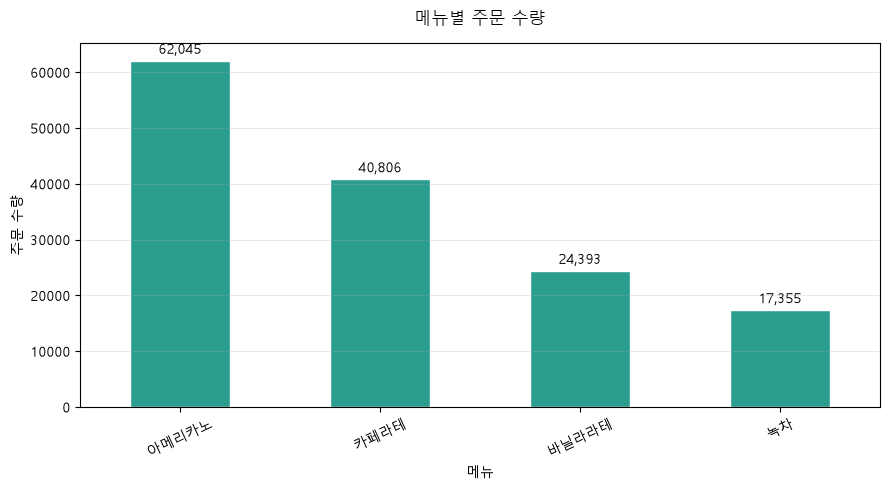

In [14]:
ax = menu_orders.plot(kind="bar", color="#2A9D8F", edgecolor="white")
show_values(ax)
decorate(ax, "메뉴별 주문 수량", "메뉴", "주문 수량", rotate=25)
plt.show()

**코드 설명**
- 핵심은 `menu_orders.plot(kind="bar")` 한 줄입니다. 요약표가 곧 그래프의 재료입니다.

**결과 해석**
- 가장 긴 막대(아메리카노)와 가장 짧은 막대(녹차)를 먼저 찾고, 실제 값의 차이를 확인합니다.
- 막대의 길이는 0부터 시작한 크기를 뜻하므로 세로축은 **0에서 시작**해야 합니다. 중간에서 시작하면 작은 차이가 크게 보입니다.

## 7. 연속형 데이터와 히스토그램

### 7-1. 값의 분포 확인하기

히스토그램은 대기시간처럼 연속적인 값이 **어느 구간에 얼마나 모여 있는지**를 보여 줍니다. 값 하나마다 막대를 만드는 대신 전체 범위를 여러 구간으로 나누고, 각 구간에 들어간 값의 개수를 막대 높이로 나타냅니다.

히스토그램에서는 값이 모여 있는 구간, 퍼진 정도, 한쪽으로 길게 늘어진 꼬리, 멀리 떨어진 값을 확인합니다. 막대그래프와 달리 구간이 이어지므로 막대를 **붙여** 그립니다. 아래는 **12개의 간단한 대기시간 예제**입니다. 값 12개를 구간 `0~2, 2~4, 4~6, 6~8, 8~10`으로 나누어 개수를 세어 봅니다.

| 구간 | 0~2분 | 2~4분 | 4~6분 | 6~8분 | 8~10분 |
|---|---|---|---|---|---|
| 값의 개수 | 3 | 5 | 3 | 0 | 1 |

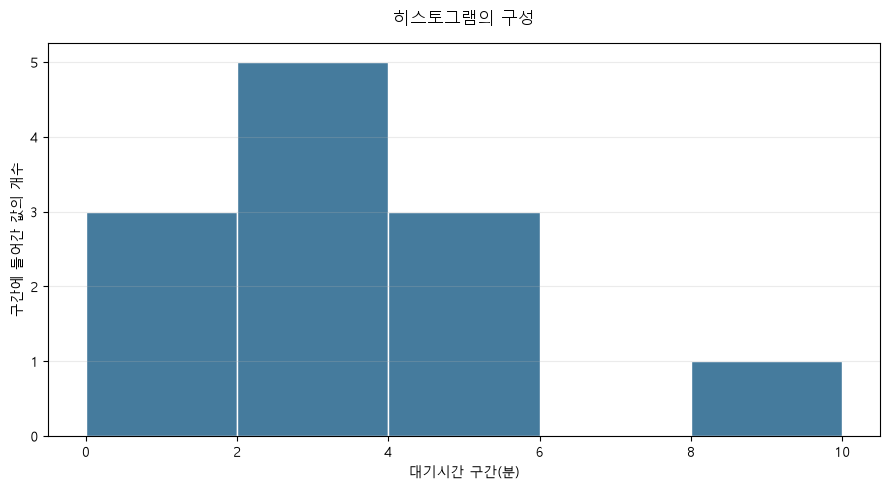

In [15]:
example_wait = pd.Series([1.0, 1.4, 1.8, 2.2, 2.7, 3.1, 3.5, 3.8, 4.4, 5.2, 5.8, 8.7])

ax = example_wait.plot(kind="hist", bins=[0, 2, 4, 6, 8, 10], color="#457B9D", edgecolor="white")
decorate(ax, "히스토그램의 구성", "대기시간 구간(분)", "구간에 들어간 값의 개수")
plt.show()

**코드 설명**
- 핵심은 `plot(kind="hist", bins=[...])`입니다. `bins`는 구간의 경계입니다.

**결과 해석**
- 막대의 높이가 표의 개수와 같습니다(3, 5, 3, 0, 1). 6~8분 구간은 값이 없어 막대가 없습니다.
- 대부분의 값이 왼쪽에 몰려 있고 오른쪽에 하나가 떨어져 있어, 오른쪽으로 긴 꼬리 모양입니다.

### 7-2. 실제 대기시간의 분포 확인하기

실제 대기시간도 같은 원리로 구간별 주문 건수를 셉니다. 먼저 평균, 중앙값, 최댓값을 확인합니다.

In [16]:
wait = data["wait_minutes"].dropna()

print("평균:", round(wait.mean(), 2), "분")
print("중앙값:", round(wait.median(), 2), "분")
print("최댓값:", round(wait.max(), 2), "분")

평균: 5.98 분
중앙값: 5.6 분
최댓값: 74.9 분


**코드 설명**
- `dropna()`는 비어 있는 값을 뺍니다.

**결과 해석**
- 평균(5.98분)이 중앙값(5.6분)보다 약간 큽니다. 큰 값 몇 개가 평균을 끌어올렸을 수 있다는 신호입니다.

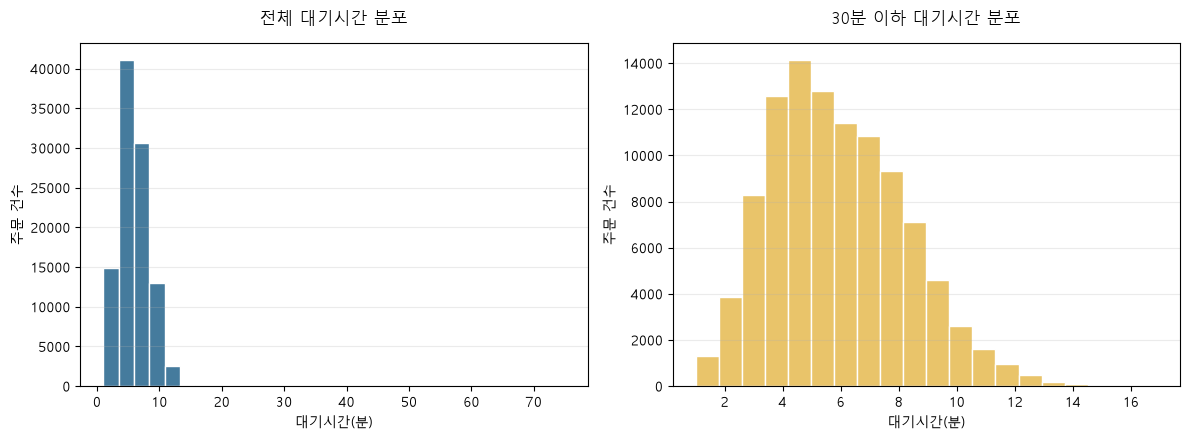

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

wait.plot(kind="hist", bins=30, ax=axes[0], color="#457B9D", edgecolor="white")
wait[wait <= 30].plot(kind="hist", bins=20, ax=axes[1], color="#E9C46A", edgecolor="white")

decorate(axes[0], "전체 대기시간 분포", "대기시간(분)", "주문 건수")
decorate(axes[1], "30분 이하 대기시간 분포", "대기시간(분)", "주문 건수")
plt.show()

**코드 설명**
- `plt.subplots(1, 2)`는 그래프를 나란히 놓을 칸 두 개를 만들고, `ax=axes[0]`, `ax=axes[1]`은 그래프를 어느 칸에 그릴지 정합니다.
- `wait[wait <= 30]`은 30분 이하만 고릅니다. `bins=30`은 구간을 30개로 나눈다는 뜻입니다.

**결과 해석**
- 왼쪽(전체)은 30분 초과 값 때문에 가로축이 70분 넘게 늘어나지만, 그 값들은 개수가 적어 막대가 보이지 않습니다. 그래서 대부분의 값이 왼쪽에 몰려 있는 것처럼 보입니다.
- 오른쪽(30분 이하)은 값이 몰린 부분을 자세히 보여 줍니다. 30분 초과를 뺀 그래프만 제시한다면 **제외했다는 사실과 기준을 반드시 밝혀야** 합니다.
- 구간 수는 여러 가지로 시험하되, 원하는 모양을 만들려고 임의로 조절해서는 안 됩니다.

## 8. 그룹별 분포와 상자그림

### 8-1. 상자그림 읽는 방법

평균 하나만 비교하면 값이 얼마나 퍼져 있는지 알 수 없습니다. 상자그림(box plot)은 **중앙값과 사분위수**로 분포를 요약해 여러 그룹을 같은 기준으로 비교합니다. 값을 작은 것부터 늘어놓고 네 부분으로 나누었을 때의 경계가 사분위수입니다.

| 용어 | 뜻 | 상자그림에서 |
|---|---|---|
| 제1사분위수(Q1) | 전체 값의 25%가 이 값 이하입니다. | 상자의 아래쪽 경계 |
| 중앙값 | 전체 값을 절반으로 나누는 값입니다. | 상자 안의 선 |
| 제3사분위수(Q3) | 전체 값의 75%가 이 값 이하입니다. | 상자의 위쪽 경계 |
| 사분위범위(IQR) | `Q3 − Q1`. 가운데 50%의 값이 퍼진 범위입니다. | 상자의 길이 |
| 수염 | 일반적인 값이 이어지는 범위입니다. | 상자에서 위아래로 뻗은 선 |
| 이상값 후보 | 수염 밖에 있는, 다른 값과 멀리 떨어진 값입니다. | 수염 밖의 점 |

**이상값은 이렇게 판단합니다.** 상자에서 IQR의 1.5배 이내까지를 일반적인 범위로 보고, 그 밖의 값을 이상값 후보로 표시합니다.

- 위쪽 한계 = `Q3 + 1.5 × IQR`
- 아래쪽 한계 = `Q1 − 1.5 × IQR`
- 위쪽 한계보다 크거나 아래쪽 한계보다 작은 값이 이상값 후보입니다. 수염은 이 한계 안에서 가장 멀리 있는 값까지 뻗습니다.

아래는 **10개의 간단한 숫자 예제**입니다. 먼저 `describe()`로 Q1(25%)과 Q3(75%)를 구하고, IQR과 두 한계를 직접 계산합니다.

In [18]:
example_box = pd.Series([1, 2, 2, 3, 3, 4, 4, 5, 6, 12])
summary_box = example_box.describe()

q1 = summary_box["25%"]
q3 = summary_box["75%"]
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
lower_limit = q1 - 1.5 * iqr

print(f"Q1 = {q1}, Q3 = {q3}")
print(f"IQR = Q3 - Q1 = {iqr}")
print(f"위쪽 한계 = {q3} + 1.5 x {iqr} = {upper_limit}")
print(f"아래쪽 한계 = {q1} - 1.5 x {iqr} = {lower_limit}")
print("이상값 후보:", example_box[example_box > upper_limit].tolist())

Q1 = 2.25, Q3 = 4.75
IQR = Q3 - Q1 = 2.5
위쪽 한계 = 4.75 + 1.5 x 2.5 = 8.5
아래쪽 한계 = 2.25 - 1.5 x 2.5 = -1.5
이상값 후보: [12]


**코드 설명**
- `describe()` 결과에서 `["25%"]`, `["75%"]`로 Q1과 Q3를 꺼내고, 위의 식 그대로 IQR과 두 한계를 계산합니다.
- `example_box[example_box > upper_limit]`은 위쪽 한계보다 큰 값만 고릅니다. 앞에서 배운 조건 추출입니다.

**결과 해석**
- Q1은 2.25, Q3는 4.75이므로 IQR은 2.5입니다. 위쪽 한계는 8.5, 아래쪽 한계는 −1.5입니다.
- 값 12는 위쪽 한계(8.5)보다 크므로 **이상값 후보**입니다. 나머지 값은 모두 한계 안에 있습니다.

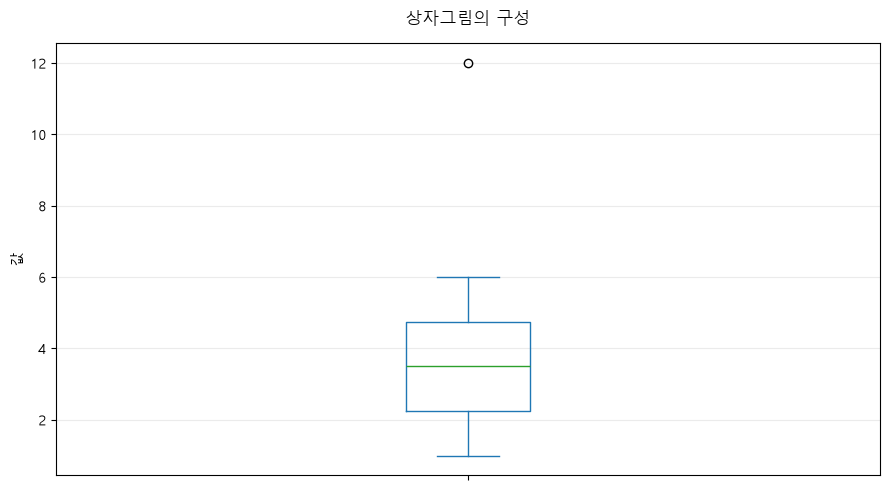

In [19]:
ax = example_box.plot(kind="box")
decorate(ax, "상자그림의 구성", "", "값")
plt.show()

**코드 설명**
- 핵심은 `plot(kind="box")`입니다. 위에서 계산한 값이 그대로 그림이 됩니다.

**결과 해석**
- 상자의 아래쪽 경계는 Q1(2.25), 위쪽 경계는 Q3(4.75)이고, 상자 안의 선은 중앙값(3.5)입니다. **상자는 가운데 50%의 값**이 있는 범위입니다.
- 수염은 한계 안에서 가장 먼 값(위쪽은 6, 아래쪽은 1)까지 뻗고, 12는 수염 밖의 점으로 따로 찍힙니다.
- 이상값 후보는 **자동으로 삭제하지 않습니다.** 입력 오류일 수도, 실제로 드문 사례일 수도 있으므로 원자료로 확인하고, 처리했다면 기준을 밝힙니다.

**읽는 순서**: 중앙값 선의 위치 → 상자의 길이 → 수염의 방향 → 수염 밖의 점

### 8-2. 실제 매장의 대기시간 비교하기

읽는 순서를 그대로 적용해 세 매장의 대기시간 분포를 비교합니다. 먼저 매장별 요약표를 만듭니다.

In [20]:
store_stats = data.groupby("store_location")["wait_minutes"].agg(["count", "mean", "median"]).round(2)
store_stats

,count,mean,median
store_location,,,
공학관점,34154,6.02,5.7
도서관점,29205,5.97,5.6
학생회관점,39025,5.95,5.6


**코드 설명**
- `agg(['count', 'mean', 'median'])`은 묶음마다 개수, 평균, 중앙값을 한 번에 계산합니다. 앞에서 쓴 방법입니다.

**결과 해석**
- 세 매장의 평균은 5.95~6.02분, 중앙값은 5.6~5.7분으로 거의 같습니다.

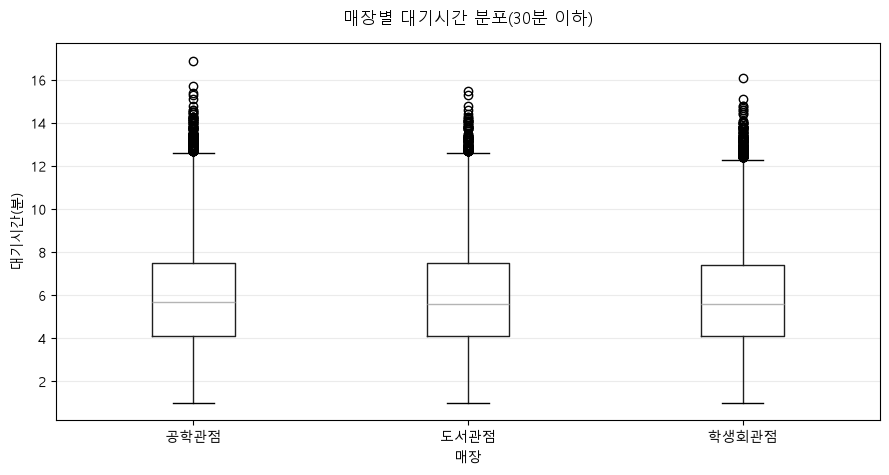

In [21]:
normal_wait = data[data["wait_minutes"] <= 30]

ax = normal_wait.boxplot(column="wait_minutes", by="store_location", grid=False)
plt.suptitle("")
decorate(ax, "매장별 대기시간 분포(30분 이하)", "매장", "대기시간(분)")
plt.show()

**코드 설명**
- 핵심은 `boxplot(column="wait_minutes", by="store_location")`입니다. `by`로 지정한 열의 값마다 상자를 하나씩 그립니다.
- 30분을 넘는 값을 뺀 `normal_wait`로 그렸습니다. 70분 가까운 값까지 한 그래프에 넣으면 상자가 납작해져 매장을 비교할 수 없기 때문입니다. 뺀 사실과 기준은 그래프 제목에 적습니다.

**결과 해석**
- 세 매장의 중앙값은 5.7분, 5.6분, 5.6분으로 0.1분 차이이고, 상자의 크기와 수염의 길이도 비슷합니다. 따라서 **매장 사이의 대기시간 차이는 거의 없다**고 읽는 것이 정확합니다.
- 수염 밖의 점이 세 매장 모두 12~17분 근처에 이어져 있습니다. 각 매장의 위쪽 한계(약 12~13분)를 넘는 값, 즉 이상값 후보입니다. 삭제하지 않고 원자료로 확인할 대상입니다. 한계의 계산은 다음 항목에서 확인합니다.
- 상자그림만 보고 어느 매장의 서비스가 나쁘다고 단정해서는 안 되며, 주문량·직원 수도 함께 살펴야 합니다.

### 8-3. 대기시간의 이상값 후보 판단하기

같은 방법을 실제 대기시간 전체에 적용합니다. 7장에서 만든 `wait`(비어 있는 값을 뺀 대기시간)를 사용합니다.

In [22]:
summary_wait = wait.describe()

q1 = summary_wait["25%"]
q3 = summary_wait["75%"]
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
lower_limit = q1 - 1.5 * iqr

print(f"Q1 = {q1}분, Q3 = {q3}분, IQR = {iqr:.1f}분")
print(f"위쪽 한계 = {upper_limit:.1f}분, 아래쪽 한계 = {lower_limit:.1f}분")
print("IQR 기준 이상값 후보:", (wait > upper_limit).sum(), "건")
print("30분 초과:", (wait > 30).sum(), "건")

Q1 = 4.1분, Q3 = 7.5분, IQR = 3.4분
위쪽 한계 = 12.6분, 아래쪽 한계 = -1.0분
IQR 기준 이상값 후보: 611 건
30분 초과: 207 건


**코드 설명**
- 앞의 예제와 같은 계산입니다. `(wait > upper_limit).sum()`은 위쪽 한계보다 큰 값이 몇 개인지 셉니다.
- 마지막 줄은 4장에서 정했던 '30분 초과' 기준으로 센 건수입니다.

**결과 해석**
- 위쪽 한계는 12.6분이고, 이를 넘는 값이 611건입니다. 아래쪽 한계는 −1.0분이어서 대기시간은 0보다 크므로 아래쪽 이상값은 없습니다.
- 앞의 상자그림에서 상자 위로 이어진 점들(12.6분 이상)이 이 611건입니다. 30분 이하 안에도 이상값 후보가 404건 있다는 뜻입니다.
- **기준에 따라 이상값 후보의 수가 달라집니다.** IQR 기준은 분포의 모양으로 정한 통계적 기준이고(611건), 30분은 '이 정도면 이상하다'는 업무 기준입니다(207건). 어느 기준이 맞는지는 분석 목적에 따라 정하며, 이상값 후보라고 해서 삭제하지 않고 원자료로 확인한 뒤 기준을 보고서에 밝힙니다.

## 9. 시간대별 변화 확인하기

### 9-1. 시간대별로 요약하기

주문 시간대(`order_hour`)를 기준으로 시간대별 주문 건수, 매출액, 평균 대기시간을 구해 앞에서 세운 분석 질문에 직접 답합니다.

이 자료에는 손님 수 열이 없으므로 **주문 한 건을 손님 한 팀의 방문**으로 보고 주문 건수를 손님 수 대신 사용합니다.

In [23]:
order_by_hour = data.groupby("order_hour")["order_id"].count()
sales_by_hour = data.groupby("order_hour")["sales_amount"].sum()
wait_by_hour = data.groupby("order_hour")["wait_minutes"].mean()

pd.DataFrame({
    "주문 건수": order_by_hour,
    "매출액(백만원)": (sales_by_hour / 1_000_000).round(1),
    "평균 대기시간(분)": wait_by_hour.round(2),
})

,주문 건수,매출액(백만원),평균 대기시간(분)
order_hour,,,
9,5579,24.2,3.97
10,6834,29.6,4.46
11,9952,42.9,5.05
12,22047,95.5,8.52
13,17436,75.7,7.18
14,8054,34.8,4.61
15,8773,37.8,4.78
16,9910,42.9,5.23
17,8621,37.3,5.01


**코드 설명**
- 세 줄 모두 `groupby("order_hour")`로 같은 시간대의 주문을 묶고, 주문 번호의 개수(`count`), 매출액의 합계(`sum`), 대기시간의 평균(`mean`)을 구합니다.
- `pd.DataFrame({...})`은 세 결과를 한 표로 나란히 놓습니다.

**결과 해석**
- 주문 건수, 매출액, 평균 대기시간이 모두 **12시에 가장 큽니다**(22,047건, 95.5백만원, 8.52분).

### 9-2. 시간대별 그래프 그리기

세 값을 시간대 순서대로 그립니다. 막대는 시간대별 크기를, 선은 시간 순서에 따른 변화를 보여 줍니다.

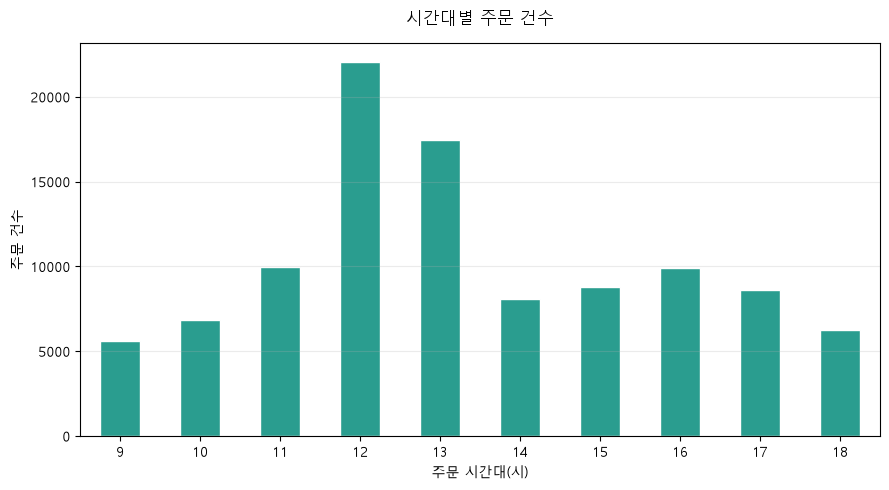

In [24]:
ax = order_by_hour.plot(kind="bar", color="#2A9D8F", edgecolor="white")
decorate(ax, "시간대별 주문 건수", "주문 시간대(시)", "주문 건수")
plt.show()

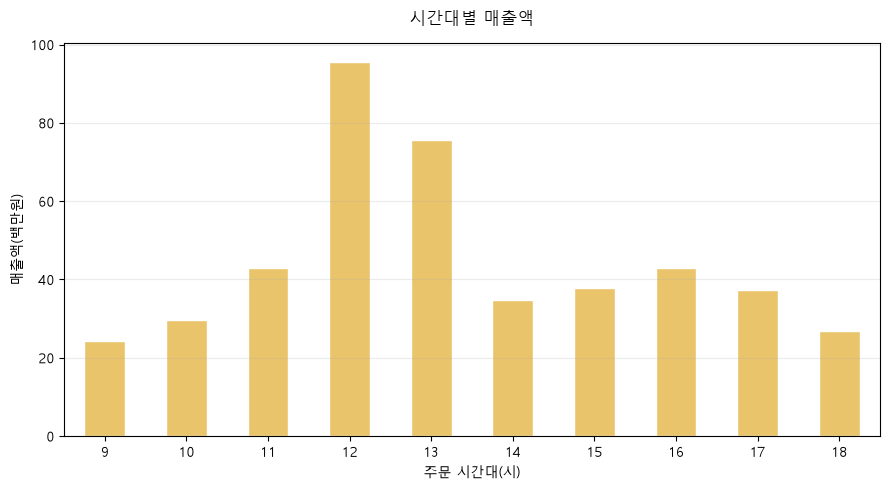

In [25]:
ax = (sales_by_hour / 1_000_000).plot(kind="bar", color="#E9C46A", edgecolor="white")
decorate(ax, "시간대별 매출액", "주문 시간대(시)", "매출액(백만원)")
plt.show()

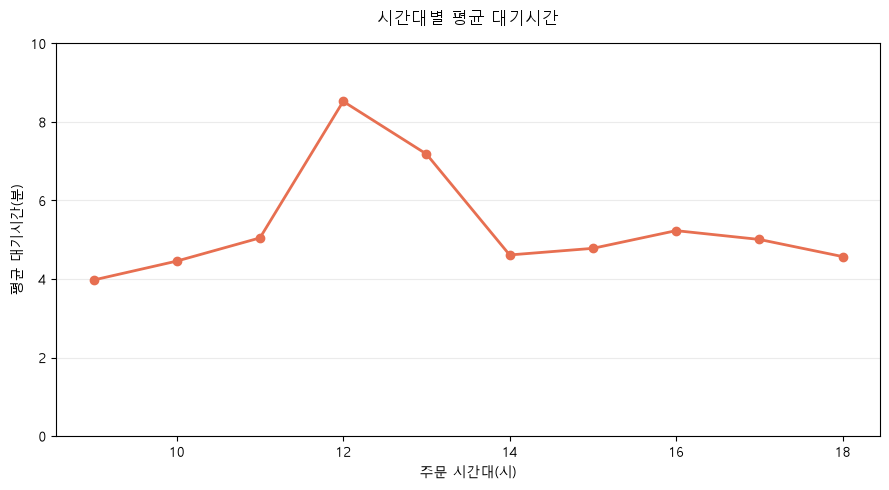

In [26]:
ax = wait_by_hour.plot(kind="line", marker="o", linewidth=2, color="#E76F51")
ax.set_ylim(0, 10)
decorate(ax, "시간대별 평균 대기시간", "주문 시간대(시)", "평균 대기시간(분)")
plt.show()

**코드 설명**
- 핵심은 각 그래프의 첫 줄입니다. 개수와 금액은 `kind="bar"`로, 시간에 따른 변화는 `kind="line"`으로 그렸습니다. `marker="o"`는 각 시점에 점을 찍습니다.

### 9-3. 시간대별 그래프 읽기

- 세 그래프 모두 **12시**가 가장 높고, 13시가 그다음입니다. 12시와 13시를 지나면 함께 줄어듭니다.
- 12시의 평균 대기시간(8.52분)은 가장 짧은 9시(3.97분)의 약 2.1배입니다.
- 18시는 주문 건수가 6,243건으로 12시의 3분의 1에 못 미치고, 평균 대기시간도 4.57분으로 짧습니다.
- 세 그래프의 모양이 비슷하다는 것은 주문이 몰리는 시간에 대기시간이 길어진다는 **단서**입니다. 다만 함께 움직인다는 사실만으로 주문 증가가 대기시간 증가의 원인이라고 말할 수는 없습니다.
- 주문 건수는 손님 수를 대신한 값이고, 6개월 전체를 합친 값이므로 요일이나 날짜별 변화는 보이지 않습니다.

## 10. 시간의 흐름과 선그래프

### 10-1. 날짜별 변화 확인하기

선그래프는 날짜, 시간처럼 **순서가 있는 값에 따른 변화**를 보여 줍니다. 가로축에 시간의 흐름, 세로축에 수치를 놓고 인접한 시점을 선으로 연결하므로 증가·감소·급격한 변동을 확인하기 쉽습니다. 주문 한 건씩 선으로 이으면 같은 날짜에 점이 너무 많아지므로, **날짜별로 먼저 합계를 낸 뒤** 그립니다.

아래는 **월요일부터 금요일까지의 간단한 매출 예제**입니다.

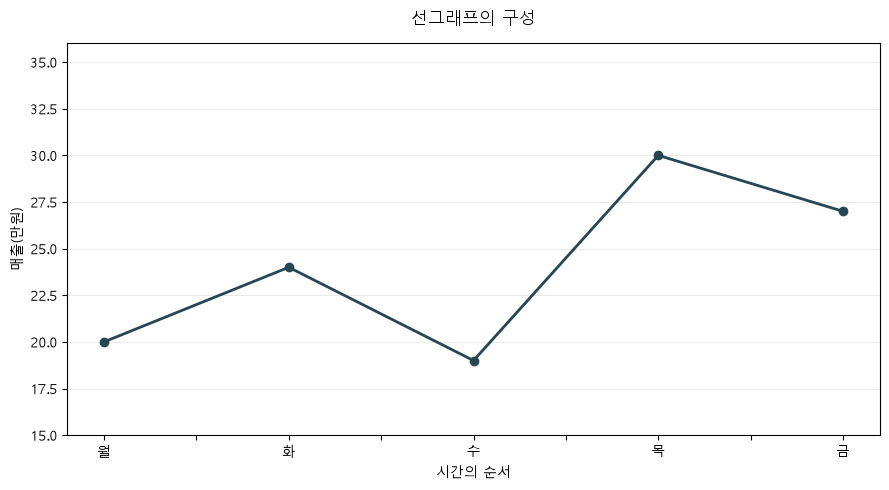

In [27]:
example_sales = pd.Series([20, 24, 19, 30, 27], index=["월", "화", "수", "목", "금"])

ax = example_sales.plot(kind="line", marker="o", linewidth=2, color="#264653")
ax.set_ylim(15, 36)
decorate(ax, "선그래프의 구성", "시간의 순서", "매출(만원)")
plt.show()

**코드 설명**
- 핵심은 `plot(kind="line", marker="o")`입니다. 점은 각 날짜의 값이고 선은 인접한 날짜 사이의 변화 방향입니다.

**결과 해석**
- 수요일(19)에서 목요일(30)로 크게 증가했고, 금요일은 조금 감소했습니다.

### 10-2. 실제 날짜별 매출 변화 확인하기

실제 데이터에서는 `groupby('order_date')`로 같은 날짜의 주문을 묶고 일 매출을 더합니다.

In [28]:
daily_sales = data.groupby("order_date")["sales_amount"].sum()
daily_sales.head()

order_date
2026-03-02    3334500
2026-03-03    3656000
2026-03-04    3288000
2026-03-05    3430000
2026-03-06    3789500
Name: sales_amount, dtype: int64

**코드 설명**
- `sum()`은 날짜마다 매출액을 합칩니다. 결과의 순서는 날짜 순서입니다.

**결과 해석**
- 처음 다섯 날의 하루 매출은 약 330만~380만 원입니다.

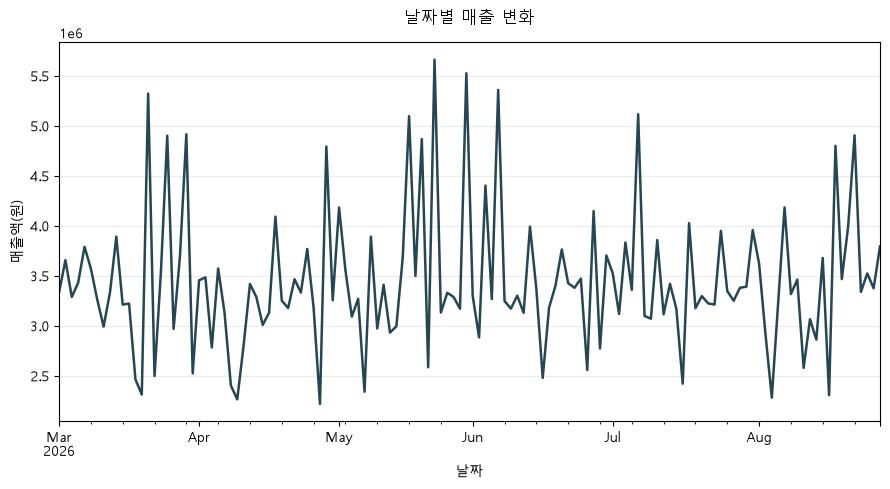

In [29]:
ax = daily_sales.plot(kind="line", color="#264653", linewidth=1.8)
decorate(ax, "날짜별 매출 변화", "날짜", "매출액(원)")
plt.show()

**코드 설명**
- 핵심은 `daily_sales.plot(kind="line")` 한 줄입니다.

**결과 해석**
- 선그래프에서는 가장 높은 시점과 낮은 시점, 갑자기 변한 구간을 먼저 찾은 뒤 **그 날짜에 무슨 일이 있었는지 원자료에서 다시 확인**합니다.

In [30]:
highest_day = daily_sales.idxmax()
lowest_day = daily_sales.idxmin()

print(f"매출이 가장 높은 날짜: {highest_day.date()} / {daily_sales.max():,.0f}원")
print(f"매출이 가장 낮은 날짜: {lowest_day.date()} / {daily_sales.min():,.0f}원")

for day in [highest_day, lowest_day]:
    one_day = data[data["order_date"] == day]
    known_weather = one_day[one_day["weather"] != "미기록"]
    print()
    print(f"[{day.date()}] 행사 여부: {one_day['event_day'].iloc[0]}")
    print("기록된 날씨별 주문 건수:")
    print(known_weather["weather"].value_counts().to_string())

매출이 가장 높은 날짜: 2026-05-22 / 5,661,500원
매출이 가장 낮은 날짜: 2026-04-28 / 2,218,000원

[2026-05-22] 행사 여부: 행사
기록된 날씨별 주문 건수:
weather
맑음      872
구름많음     53

[2026-04-28] 행사 여부: 일반
기록된 날씨별 주문 건수:
weather
비     342
흐림     23


**코드 설명**
- `idxmax()`와 `idxmin()`은 가장 큰 값과 가장 작은 값의 **날짜(레이블)**를 알려 줍니다.
- `for day in [...]`는 두 날짜에 대해 같은 출력을 차례로 반복합니다. `data[data["order_date"] == day]`는 그 날짜의 행만 고릅니다.

**결과 해석**
- 매출이 가장 높은 날(2026-05-22)은 **행사일**이고, 가장 낮은 날(2026-04-28)은 일반일이며 기록된 날씨 대부분이 **비**입니다. 선그래프에서 눈에 띄는 날짜를 원자료로 확인하면 이유를 짐작할 수 있습니다.

## 11. 두 수치의 관계와 산점도

### 11-1. 두 수치를 점으로 나타내기

산점도는 **두 수치가 함께 어떻게 움직이는지**를 보여 줍니다. 가로축에 한 수치, 세로축에 다른 수치를 놓고 관측값 하나를 점 하나로 찍습니다. 점을 선으로 잇지 않고, 점들이 전체적으로 어떤 모양인지 읽습니다.

- 점들이 **오른쪽 위로** 올라가는가(함께 증가), **오른쪽 아래로** 내려가는가(한쪽이 늘면 다른 쪽이 줄어듦), 방향이 없는가
- 점들이 한 줄에 모였는가, 넓게 흩어졌는가
- 멀리 떨어진 점이 있는가

아래는 **10개의 간단한 예제**입니다.

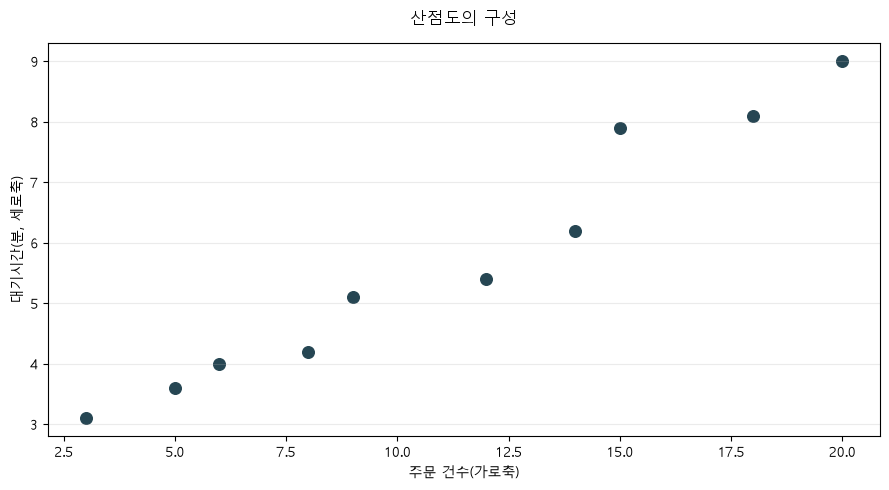

In [31]:
example = pd.DataFrame({
    "주문건수": [3, 5, 6, 8, 9, 12, 14, 15, 18, 20],
    "대기시간": [3.1, 3.6, 4.0, 4.2, 5.1, 5.4, 6.2, 7.9, 8.1, 9.0],
})

ax = example.plot(kind="scatter", x="주문건수", y="대기시간", s=70, color="#264653")
decorate(ax, "산점도의 구성", "주문 건수(가로축)", "대기시간(분, 세로축)")
plt.show()

**코드 설명**
- 핵심은 `plot(kind="scatter", x=..., y=...)`입니다. `x`와 `y`에 가로축과 세로축으로 쓸 열 이름을 적습니다.

**결과 해석**
- 점들이 오른쪽 위로 올라갑니다. 주문 건수가 많을수록 대기시간이 길어지는 **양의 관계**입니다.

### 11-2. 실제 데이터로 산점도 만들기

실제 데이터의 점 하나는 **하루 안의 한 매장·한 시간대**로 정합니다. 주문 한 건씩 찍으면 가로축 값이 모두 1이 되어 관계를 볼 수 없기 때문입니다. 날짜, 매장, 시간대가 모두 같은 주문을 묶어 주문 건수와 평균 대기시간을 구합니다.

In [32]:
group_keys = ["order_date", "store_location", "order_hour"]

slot_orders = data.groupby(group_keys)["order_id"].count()
slot_wait = data.groupby(group_keys)["wait_minutes"].mean()

slot = pd.DataFrame({"주문건수": slot_orders, "평균대기시간": slot_wait})
print(f"점의 개수: {len(slot):,}개")
slot.head()

점의 개수: 3,900개


주문건수    평균대기시간
order_date store_location order_hour                
2026-03-02 공학관점           9             16  4.520000
                          10            13  4.969231
                          11            20  5.478947
                          12            52  9.609615
                          13            51  7.715686

**코드 설명**
- `groupby(group_keys)`는 세 가지 기준이 모두 같은 주문끼리 묶습니다. 이후는 앞에서 쓴 `count()`와 `mean()`과 같습니다.
- 두 결과를 `pd.DataFrame({...})`으로 한 표에 놓으면 한 줄이 점 하나가 됩니다.

**결과 해석**
- 점이 3,900개입니다. 130일 × 3개 매장 × 10개 시간대입니다.

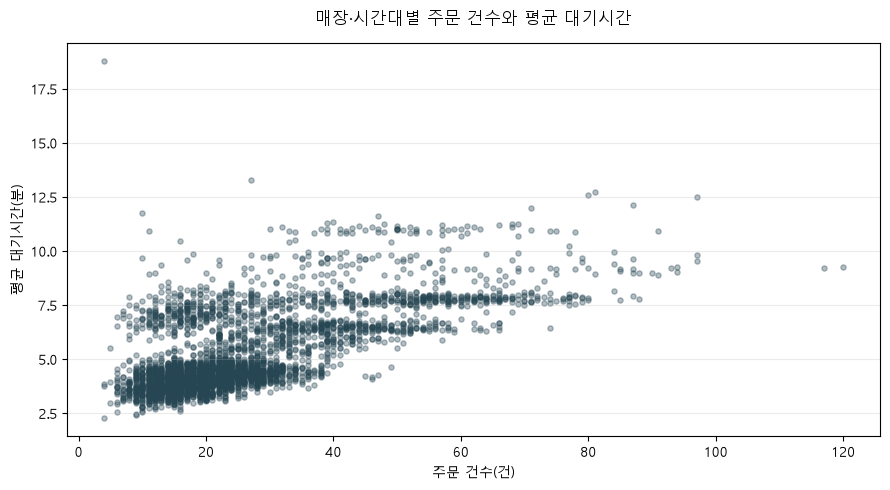

In [33]:
ax = slot.plot(kind="scatter", x="주문건수", y="평균대기시간", s=14, alpha=0.35, color="#264653")
decorate(ax, "매장·시간대별 주문 건수와 평균 대기시간", "주문 건수(건)", "평균 대기시간(분)")
plt.show()

**코드 설명**
- 핵심은 `plot(kind="scatter", ...)` 한 줄입니다. 점이 많아 `alpha=0.35`로 투명하게 하면 겹친 부분이 더 진하게 보입니다.

### 11-3. 산점도 읽기

- 점이 오른쪽 위로 올라가는 모양입니다. **주문 건수가 많은 매장·시간대일수록 평균 대기시간이 긴 경향**이 있습니다.
- 점들이 한 줄이 아니라 여러 높이의 띠로 나뉘어 있습니다. 주문 건수가 같아도 대기시간이 다르므로, 주문 건수만으로 대기시간이 정해지는 것은 아닙니다.
- 산점도는 두 값이 **함께 움직인다**는 사실을 보여 줄 뿐, 한쪽이 다른 쪽의 원인이라는 증거가 아닙니다. 주문이 몰리는 시간에는 직원 배치와 메뉴 구성도 함께 달라집니다.

### 11-4. 상관계수로 관계의 세기 나타내기 (선택)

점들이 한 줄에 얼마나 가까운지를 숫자 하나로 나타낸 것이 **상관계수**입니다. −1에서 1 사이의 값이며, 1에 가까울수록 함께 증가하는 관계가 뚜렷하고, 0에 가까울수록 관계가 없습니다.

In [34]:
print("상관계수:", round(slot["주문건수"].corr(slot["평균대기시간"]), 2))

상관계수: 0.67


**결과 해석**
- 0.67이므로 비교적 뚜렷한 양의 관계입니다. 상관계수가 커도 원인을 뜻하지는 않습니다.

### 11-5. 직원 수로 점의 색 나누기 (선택)

점의 색으로 세 번째 값을 함께 나타낼 수 있습니다. 직원 수를 색으로 나누어 봅니다.

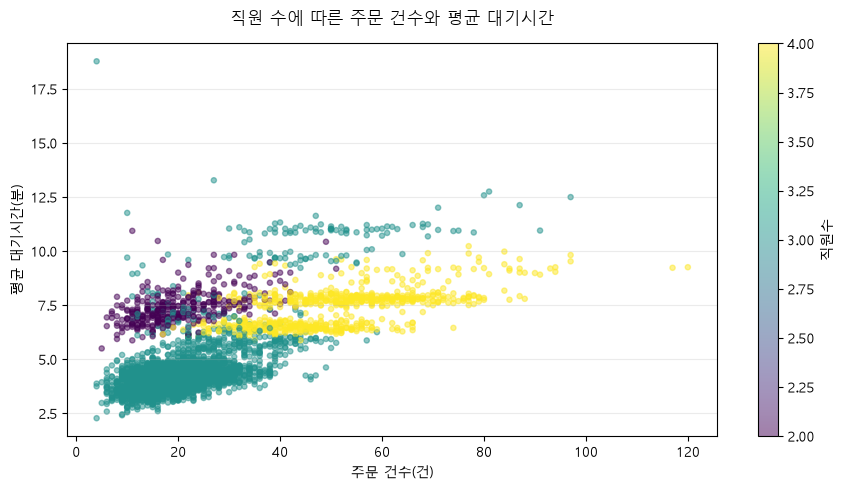

In [35]:
slot["직원수"] = data.groupby(group_keys)["staff_count"].mean()

ax = slot.plot(kind="scatter", x="주문건수", y="평균대기시간", c="직원수",
               colormap="viridis", s=14, alpha=0.5)
decorate(ax, "직원 수에 따른 주문 건수와 평균 대기시간", "주문 건수(건)", "평균 대기시간(분)")
plt.show()

**코드 설명**
- `c="직원수"`는 점의 색을 직원 수에 따라 정합니다. 오른쪽의 색 막대가 색과 직원 수의 대응입니다.

**결과 해석**
- 색은 보라(2명), 청록(3명), 노랑(4명)입니다. 주문 건수가 비슷한 곳에서 **직원이 적은 점이 더 위쪽**에 놓입니다. 같은 주문 규모에서도 직원이 적을 때 대기시간이 긴 경향이 있습니다.
- 이것도 원인을 확정하는 증거는 아닙니다. 직원 배치는 주문이 몰리는 시간에 맞춰 달라지는 조건이기 때문입니다.

## 12. 두 범주를 함께 비교하기 (선택)

### 12-1. 묶은 막대그래프로 조건 비교하기

매장과 행사 여부처럼 **두 범주를 동시에 비교**하려면 각 매장 안에 행사일과 일반일 막대를 나란히 놓습니다. 이를 묶은 막대그래프라고 합니다. 같은 색의 막대는 같은 조건이므로 범례를 함께 읽습니다.

무엇을 비교할지는 질문에 맞게 정합니다. 행사일에 달라지는 것은 주문 한 건의 금액보다 **하루에 들어오는 주문의 수**일 가능성이 큽니다. 그래서 하루의 주문 건수를 먼저 센 뒤 평균을 비교합니다.

In [36]:
daily_orders = data.groupby(["store_location", "event_day", "order_date"])["order_id"].count()
event_orders = daily_orders.groupby(["store_location", "event_day"]).mean().unstack()

print("행사 여부별 날짜 수:")
print(data.groupby("event_day")["order_date"].nunique())
event_orders.round(0)

행사 여부별 날짜 수:
event_day
일반    116
행사     14
Name: order_date, dtype: int64


event_day,일반,행사
store_location,,
공학관점,251.0,380.0
도서관점,215.0,324.0
학생회관점,287.0,439.0


**코드 설명**
- 첫 줄은 매장·행사 여부·날짜별로 **하루의 주문 건수**를 셉니다. 둘째 줄은 그 값을 매장과 행사 여부별로 평균 내고, `unstack()`으로 행사 여부를 열로 옮겨 두 값을 나란히 놓은 표를 만듭니다.

**결과 해석**
- 행사일은 14일, 일반일은 116일입니다. 행사일 수가 적으므로 평균이 일부 날짜의 영향을 받을 수 있습니다.

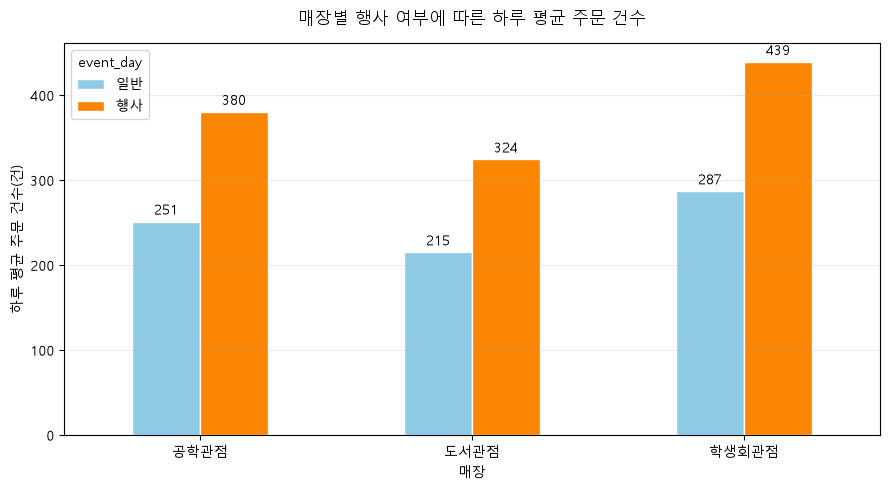

In [37]:
ax = event_orders.plot(kind="bar", color=["#8ECAE6", "#FB8500"], edgecolor="white")
show_values(ax)
decorate(ax, "매장별 행사 여부에 따른 하루 평균 주문 건수", "매장", "하루 평균 주문 건수(건)")
plt.show()

**코드 설명**
- 표의 열이 두 개이므로 `plot(kind="bar")`가 열마다 막대를 하나씩 그려 묶은 막대그래프가 됩니다.

**결과 해석**
- 세 매장 모두 행사일의 하루 평균 주문 건수가 일반일보다 약 1.5배 많습니다(예: 공학관점 251건 → 380건).
- 행사가 주문 증가의 **원인**이라고 바로 말할 수는 없습니다. 요일, 날씨 등 다른 조건도 달라질 수 있습니다.
- 주문당 평균 매출로 비교하면 두 막대가 거의 같아 행사의 영향이 보이지 않습니다. 같은 자료도 **어떤 지표를 고르느냐**에 따라 결론이 달라지므로 질문에 맞는 지표를 먼저 정해야 합니다.

## 13. 그래프를 문장으로 해석하기

### 13-1. 사실·비교·한계로 설명하기

그래프 설명은 세 부분으로 쓰면 명확합니다.

1. **사실**: 그래프에서 직접 확인한 값이나 순위
2. **비교**: 가장 큰 값과 작은 값, 또는 기준 집단과의 차이
3. **해석과 한계**: 가능한 의미를 쓰되, 그래프만으로 확인할 수 없는 원인은 단정하지 않기

설명에 필요한 핵심 수치를 다시 계산합니다.

In [38]:
top_menu = menu_orders.idxmax()
top_menu_count = int(menu_orders.max())
peak_order_hour = order_by_hour.idxmax()
peak_wait_hour = wait_by_hour.idxmax()
store_gap = store_stats["median"].max() - store_stats["median"].min()

print(f"주문 수량이 가장 많은 메뉴: {top_menu} ({top_menu_count:,}개)")
print(f"주문 건수가 가장 많은 시간대: {peak_order_hour}시")
print(f"평균 대기시간이 가장 긴 시간대: {peak_wait_hour}시 ({wait_by_hour.max():.1f}분)")
print(f"매장 간 중앙 대기시간의 차이: {store_gap:.1f}분")

주문 수량이 가장 많은 메뉴: 아메리카노 (62,045개)
주문 건수가 가장 많은 시간대: 12시
평균 대기시간이 가장 긴 시간대: 12시 (8.5분)
매장 간 중앙 대기시간의 차이: 0.1분


설명 예시는 다음과 같습니다.

> 시간대별로 비교한 결과 12시의 평균 대기시간이 8.5분으로 가장 길었고, 주문 건수도 가장 많았다. 매장·시간대별 산점도에서도 주문 건수가 많을수록 평균 대기시간이 길어지는 경향이 나타났다. 다만 이 자료로는 주문 증가가 대기시간 증가의 원인인지 직원 배치나 메뉴 구성의 영향인지 구분할 수 없다. 세 매장의 중앙 대기시간은 차이가 0.1분이어서 매장 사이의 차이는 확인되지 않았다.

숫자와 그래프가 보여 주는 범위를 넘어서지 않는 것이 중요합니다.

## 14. 그래프 표현 방식 점검하기

### 14-1. 축의 시작점과 범위 확인하기

같은 값도 세로축을 어디서 시작하느냐에 따라 차이가 매우 크게 보일 수 있습니다. 아래 두 그래프는 같은 매장별 평균 주문 금액을 사용합니다.

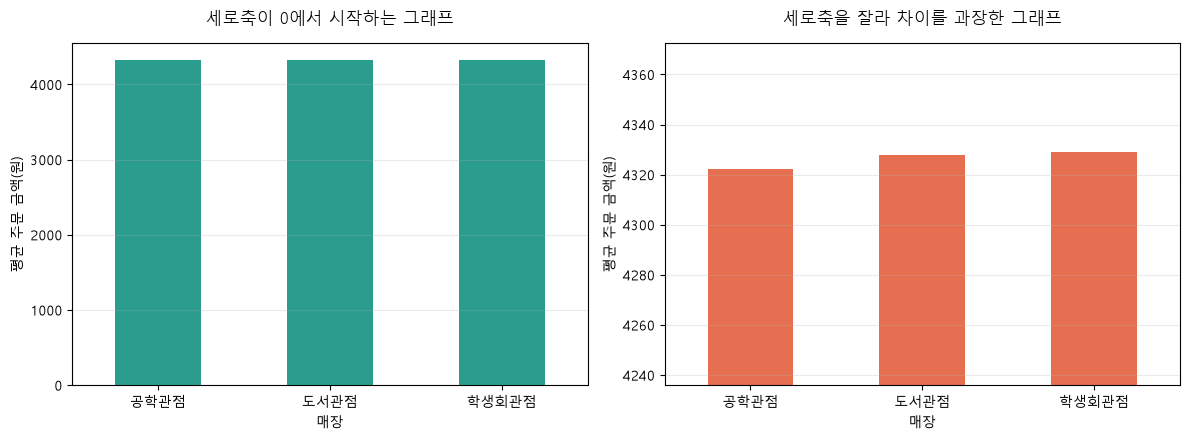

In [39]:
store_avg_sales = data.groupby("store_location")["sales_amount"].mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

store_avg_sales.plot(kind="bar", ax=axes[0], color="#2A9D8F")
store_avg_sales.plot(kind="bar", ax=axes[1], color="#E76F51")
axes[1].set_ylim(store_avg_sales.min() * 0.98, store_avg_sales.max() * 1.01)

decorate(axes[0], "세로축이 0에서 시작하는 그래프", "매장", "평균 주문 금액(원)")
decorate(axes[1], "세로축을 잘라 차이를 과장한 그래프", "매장", "평균 주문 금액(원)")
plt.show()

**코드 설명**
- 두 그래프는 같은 자료를 씁니다. 오른쪽에서만 `set_ylim()`으로 세로축의 시작점을 최솟값 근처로 올렸습니다.

**결과 해석**
- 왼쪽에서는 세 매장이 거의 같아 보이는데, 오른쪽에서는 큰 차이가 있는 것처럼 보입니다. 막대의 길이는 0부터의 크기를 나타내므로 **세로축을 자르면 차이가 과장**됩니다.
- 그래프를 읽을 때는 제목뿐 아니라 **축의 시작점, 단위, 범위, 제외된 값, 집계 기준**을 함께 확인합니다.

## 15. 분석 결과 종합 확인하기

### 15-1. 핵심 결과 한눈에 확인하기

여러 그래프를 만든 뒤에는 분석에 사용한 데이터의 범위와 핵심 수치를 다시 확인합니다. 아래 표는 앞에서 계산한 결과가 서로 일치하는지 확인하는 **종합 확인표**입니다.

In [40]:
summary = pd.DataFrame({
    "항목": [
        "분석 행 수",
        "분석 기간",
        "총 주문 수량",
        "총 매출액",
        "평균 대기시간",
        "중앙 대기시간",
        "가장 많이 주문된 메뉴",
        "주문이 가장 많은 시간대",
        "평균 대기시간이 가장 긴 시간대",
    ],
    "결과": [
        f"{len(data):,}행",
        f"{data['order_date'].min().date()} ~ {data['order_date'].max().date()}",
        f"{data['order_count'].sum():,}개",
        f"{data['sales_amount'].sum():,.0f}원",
        f"{data['wait_minutes'].mean():.2f}분",
        f"{data['wait_minutes'].median():.2f}분",
        top_menu,
        f"{peak_order_hour}시 ({order_by_hour.max():,}건)",
        f"{peak_wait_hour}시 ({wait_by_hour.max():.2f}분)",
    ]
})
summary

,항목,결과
0,분석 행 수,"103,449행"
1,분석 기간,2026-03-02 ~ 2026-08-28
2,총 주문 수량,"144,599개"
3,총 매출액,"447,570,500원"
4,평균 대기시간,5.98분
5,중앙 대기시간,5.60분
6,가장 많이 주문된 메뉴,아메리카노
7,주문이 가장 많은 시간대,"12시 (22,047건)"
8,평균 대기시간이 가장 긴 시간대,12시 (8.52분)


### 15-2. 최종 점검

- 분석 질문과 그래프가 일치하는가?
- 그래프를 만들기 전에 요약표를 확인했는가?
- 제목, 축 이름, 단위가 적혀 있는가?
- 결측값, 중복값, 범위 오류의 처리 방법을 밝혔는가?
- 축의 범위나 제외 조건이 차이를 과장하지 않는가?
- 질문에 맞는 지표를 골랐는가?
- 두 값이 함께 움직인다는 사실을 원인으로 단정하지 않았는가?
- 관찰한 사실과 해석을 구분했는가?